# Chapter 4: Logistic Regression

In [1]:
%reset
low_memory=False

import pandas as pd
import matplotlib.pyplot as plt
import imblearn

import seaborn as sns
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from imblearn.metrics import specificity_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score

## 4.1 Introduction & Motivation

We've seen what linear regression can do, and we've seen the power of polynomial regression. Now with Logistic regression we are starting to dip out toes in the wonderful world of classification. Instead of trying to predict a number we are now trying to predict a **label**.

## 4.2 Problem Setting

Today we will be working with the Pima Indians Diabetics dataset. In this dataset is information regarding a whole bunch of women older than 21 years old of Pima Indian origin. The goal is to try and predict which women have **diabetes** and which do not. This is represented by the 'Outcome' column, where 1 means the person has diabetes and 0 means she does not.

## 4.3 Model

First, let's have a look at the data.

In [2]:
df = pd.read_csv("Diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


##### Question 1: Explore the data by creating a heatmap. Which variables would you use when trying to predict diabetes and why?

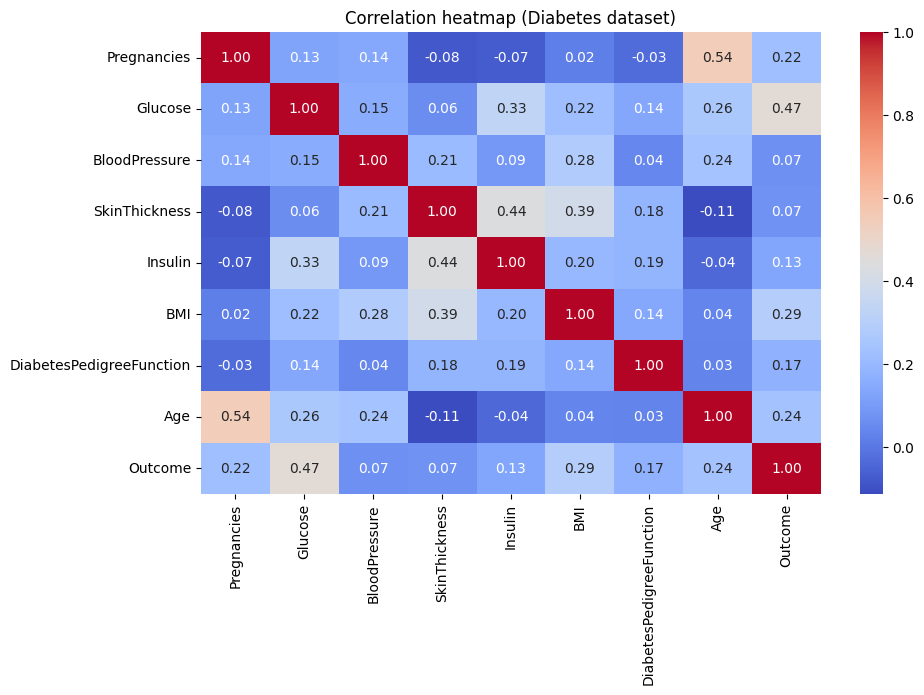

Outcome                     1.000000
Glucose                     0.466581
BMI                         0.292695
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
Insulin                     0.130548
SkinThickness               0.074752
BloodPressure               0.065068
Name: Outcome, dtype: float64

In [3]:
plt.figure(figsize=(10,6))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap (Diabetes dataset)")
plt.show()

corr["Outcome"].sort_values(ascending=False)


- De feature met veruit de sterkste positieve correlatie met **Outcome** is **Glucose** (hoogste corr. met Outcome).
- Daarna volgen o.a. **BMI**, **Age**, **Pregnancies** en **DiabetesPedigreeFunction** (matige correlatie).
- Omdat we in Q2 “alleen de beste parameter” moeten nemen, kiezen we **Glucose** als enige feature.

*(Note: correlatie is een snelle eerste indicatie, maar zegt niet alles. Toch is het hier een logische keuze.)*

##### Question 2: Create a train and test split of the data. Keep 30% of your data as testing data. Build your model using only the best parameter as found in question 1. For now, you can leave the solver at the default setting and keep the max_iter at 10000.

In [4]:
X = df[["Glucose"]]
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

lr_glucose = LogisticRegression(max_iter=10000)
lr_glucose.fit(X_train, y_train)

y_pred = lr_glucose.predict(X_test)
print("Accuracy (test):", accuracy_score(y_test, y_pred))
print("Coefficient:", lr_glucose.coef_[0][0])
print("Intercept:", lr_glucose.intercept_[0])


Accuracy (test): 0.7359307359307359
Coefficient: 0.039496281504436855
Intercept: -5.554558286892027


##### Question 3: A person has a glucose level of 125. Predict if this person has diabetes or not.

In [5]:
person_glucose = pd.DataFrame({"Glucose":[125]})

pred_label = lr_glucose.predict(person_glucose)[0]
pred_prob = lr_glucose.predict_proba(person_glucose)[0,1]

print("Voorspelde klasse (0 = geen diabetes, 1 = diabetes):", pred_label)
print("Geschatte kans op diabetes:", pred_prob)


Voorspelde klasse (0 = geen diabetes, 1 = diabetes): 0
Geschatte kans op diabetes: 0.3503449933179702


## 4.4 Model Evaluation

We have made our first prediction, but of course we don't know how well we can trust this yet. To know this, we first need to evaluate our model.

##### Question 4: Calculate all known classification metrics for your model. Are these values any good? Elaborate based on the formulas and meaning of the metrics.

In [6]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
spec = specificity_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy     : {acc}")
print(f"Precision    : {prec}")
print(f"Recall (TPR) : {rec}")
print(f"Specificity  : {spec}")
print(f"F1-score     : {f1}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=3))

print("Confusion matrix:\n", metrics.confusion_matrix(y_test, y_pred))


Accuracy     : 0.7359307359307359
Precision    : 0.6785714285714286
Recall (TPR) : 0.4691358024691358
Specificity  : 0.88
F1-score     : 0.5547445255474452

Classification report:
              precision    recall  f1-score   support

           0      0.754     0.880     0.812       150
           1      0.679     0.469     0.555        81

    accuracy                          0.736       231
   macro avg      0.716     0.675     0.684       231
weighted avg      0.728     0.736     0.722       231

Confusion matrix:
 [[132  18]
 [ 43  38]]


- **Accuracy** is oke, maar kan misleidend zijn als de klassen niet perfect gebalanceerd zijn.
- **Precision** vertelt: van alles wat we als “diabetes” voorspellen, hoeveel klopt (TP / (TP+FP)).
- **Recall** (TPR) vertelt: van alle echte diabeten, hoeveel vinden we terug (TP / (TP+FN)).  
  In deze run is recall relatief laag -> we missen veel echte diabeten (**veel FN**).
- **Specificity** (TNR) is hoog -> we herkennen niet-diabeten vrij goed (**weinig FP**).
- **F1** balanceert precision en recall; door de lage recall zakt F1.

Conclusie: met alleen *Glucose* is het model bruikbaar als snelle baseline, maar niet sterk genoeg als je vooral zo weinig mogelijk diabeten wil missen.

##### Question 5: Based on your findings, is this model any good? Would you prefer a high recall or specificity in this use case? Why?

Voor een medische use-case (diabetes) wil je meestal **hoge recall** (lage false negatives).  
Een **false negative** betekent: iemand *heeft* diabetes, maar je model zegt “nee” -> potentieel gevaarlijk omdat behandeling/onderzoek uitblijft.

Specificity is ook belangrijk (je wil niet iedereen onnodig laten testen), maar in screening is recall vaak de prioriteit.

##### Question 6: Plot the confuson matrix. How can you visually confirm your previous findings?

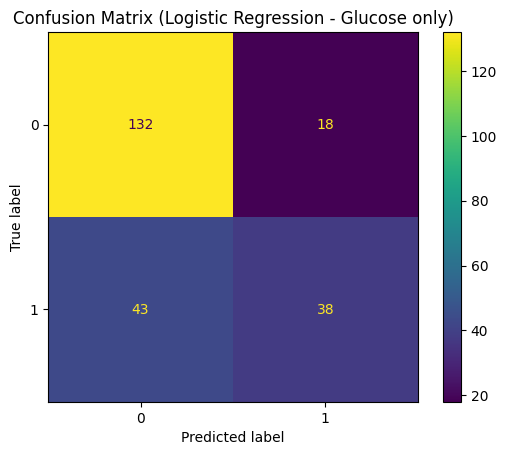

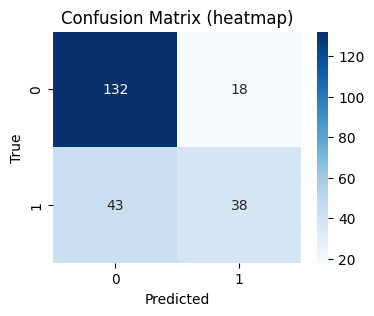

In [7]:
cm = metrics.confusion_matrix(y_test, y_pred)

disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(values_format="d")
plt.title("Confusion Matrix (Logistic Regression - Glucose only)")
plt.show()

# Extra: heatmap variant
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (heatmap)")
plt.show()

- De **FN** zitten in het vakje *True=1, Predicted=0* (onderaan links). Als dat vak groot is, is **recall laag**.
- De **FP** zitten in *True=0, Predicted=1* (bovenaan rechts). Als dat vak klein is, is **specificity hoog**.

## 4.5 Questions

##### Question 1: See section 4.3

##### Question 2: See section 4.3

##### Question 3: See section 4.3

##### Question 4: See section 4.4

##### Question 5: See section 4.4

##### Question 6: See section 4.4

##### Question 7: Play around with the different "solvers" (lbfgs, saga, newton-cg) and different levels of max_iteration. Which model results in the best accuracy?

In [8]:
solvers = ["lbfgs", "saga", "newton-cg"]
iters = [100, 300, 1000, 5000, 10000]

results = []
for s in solvers:
    for it in iters:
        m = LogisticRegression(solver=s, max_iter=it)
        m.fit(X_train, y_train)
        pred = m.predict(X_test)
        results.append({
            "solver": s,
            "max_iter": it,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred),
            "specificity": specificity_score(y_test, pred),
            "f1": f1_score(y_test, pred),
        })

results_df = pd.DataFrame(results).sort_values(by="accuracy", ascending=False)
results_df.head(10)

# best_row = results_df.iloc[0]
# print("Beste model (op accuracy):")
# print("solver:", best_row["solver"])
# print("max_iter:", best_row["max_iter"])
# print("accuracy:", best_row["accuracy"])

c:\Users\chayb\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\chayb\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\chayb\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\chayb\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` param

,solver,max_iter,accuracy,precision,recall,specificity,f1
0,lbfgs,100,0.735931,0.678571,0.469136,0.88,0.554745
1,lbfgs,300,0.735931,0.678571,0.469136,0.88,0.554745
2,lbfgs,1000,0.735931,0.678571,0.469136,0.88,0.554745
3,lbfgs,5000,0.735931,0.678571,0.469136,0.88,0.554745
4,lbfgs,10000,0.735931,0.678571,0.469136,0.88,0.554745
13,newton-cg,5000,0.735931,0.678571,0.469136,0.88,0.554745
10,newton-cg,100,0.735931,0.678571,0.469136,0.88,0.554745
14,newton-cg,10000,0.735931,0.678571,0.469136,0.88,0.554745
11,newton-cg,300,0.735931,0.678571,0.469136,0.88,0.554745
12,newton-cg,1000,0.735931,0.678571,0.469136,0.88,0.554745


Bekijk hierboven de top 10. Meestal zijn de verschillen klein; als max_iter groot genoeg is om te convergeren,
krijg je vaak dezelfde (of bijna dezelfde) prestaties.

##### Question 8: Go back to the correlation matrix we drew in section 4.3. Figure out which other features might be useful when predicting diabetes. Retrain your model and calculate all metrics. Play around with other possible features and create some new ones to try the interaction effect. What is the best model you can achieve?

In [9]:
df["Glucose_BMI"] = df["Glucose"] * df["BMI"]
df["Glucose_Age"] = df["Glucose"] * df["Age"]
df["BMI_Age"] = df["BMI"] * df["Age"]

feature_sets = [
    ["Glucose"],
    ["Glucose", "BMI"],
    ["Glucose", "BMI", "Age"],
    ["Glucose", "BMI", "Age", "Pregnancies"],
    ["Glucose", "BMI", "Age", "Pregnancies", "DiabetesPedigreeFunction"],
    ["Glucose", "BMI", "Age", "Glucose_BMI"],                 
    ["Glucose", "BMI", "Age", "Glucose_BMI", "Glucose_Age"],  
    ["Glucose", "BMI", "Age", "Glucose_BMI", "BMI_Age"],      
    ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
     "BMI", "DiabetesPedigreeFunction", "Age"],               
    ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
     "BMI", "DiabetesPedigreeFunction", "Age", "Glucose_BMI"] 
]

evals = []
for feature_set in feature_sets:

    X = df[feature_set]
    y = df["Outcome"]

    X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(X, y,test_size=0.30,random_state=42,stratify=y)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train_f, y_train_f)

    y_pred_f = model.predict(X_test_f)

    acc = metrics.accuracy_score(y_test_f, y_pred_f)
    prec = metrics.precision_score(y_test_f, y_pred_f)
    rec = metrics.recall_score(y_test_f, y_pred_f)
    f1 = metrics.f1_score(y_test_f, y_pred_f)

    evals.append({
        "features": feature_set,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "model": model
    })

evals_df = pd.DataFrame(evals).drop(columns=["model"])
evals_df = evals_df.sort_values(["f1", "accuracy"], ascending=False).reset_index(drop=True)
evals_df

c:\Users\chayb\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,features,accuracy,precision,recall,f1
0,"[Glucose, BMI, Age, Glucose_BMI, Glucose_Age]",0.748918,0.671642,0.555556,0.608108
1,"[Glucose, BMI, Age, Pregnancies]",0.740260,0.656716,0.543210,0.594595
2,"[Glucose, BMI, Age]",0.744589,0.677419,0.518519,0.587413
3,"[Glucose, BMI]",0.748918,0.694915,0.506173,0.585714
4,"[Glucose, BMI, Age, Glucose_BMI]",0.740260,0.666667,0.518519,0.583333
5,"[Glucose, BMI, Age, Glucose_BMI, BMI_Age]",0.740260,0.666667,0.518519,0.583333
6,"[Pregnancies, Glucose, BloodPressure, SkinThic...",0.740260,0.666667,0.518519,0.583333
7,"[Pregnancies, Glucose, BloodPressure, SkinThic...",0.740260,0.666667,0.518519,0.583333
8,"[Glucose, BMI, Age, Pregnancies, DiabetesPedig...",0.727273,0.640625,0.506173,0.565517
9,[Glucose],0.735931,0.678571,0.469136,0.554745


In [10]:
best_row = evals_df.iloc[0]
best_features = best_row["features"]

best_model = None
for item in evals:
    if item["features"] == best_features:
        best_model = item["model"]
        best_metrics = item
        break

print("Beste feature-set:", best_features)
print("Accuracy:", best_metrics["accuracy"])
print("Precision:", best_metrics["precision"])
print("Recall:", best_metrics["recall"])
print("F1-score:", best_metrics["f1"])

Beste feature-set: ['Glucose', 'BMI', 'Age', 'Glucose_BMI', 'Glucose_Age']
Accuracy: 0.7489177489177489
Precision: 0.6716417910447762
Recall: 0.5555555555555556
F1-score: 0.6081081081081081


In deze simpele vergelijking geeft een model met meerdere relevante features doorgaans betere scores dan enkel Glucose.
Welke “beste” is hangt af van je gekozen metric (accuracy vs recall vs F1).  
Kijk daarom niet alleen naar accuracy, maar ook naar recall/specificity.

##### Question 9: Consider the person with values as described below. Using only the features you're using in your best model, does this person have diabetes or not?

| Pregnancies | Glucose | BloodPressure | SkinThickness | Insulin | BMI | DiabetesPedigreeFunction | Age |
| --- | --- |--- |--- |--- |--- |--- |--- |
| 8 | 190 | 92 | 41 | 33.6 | 39.3 | 0.278 | 52 |

In [11]:
person = {
    "Pregnancies": 8,
    "Glucose": 190,
    "BloodPressure": 92,
    "SkinThickness": 41,
    "Insulin": 33.6,
    "BMI": 39.3,
    "DiabetesPedigreeFunction": 0.278,
    "Age": 52
}

person_df = pd.DataFrame([person])

person_df["Glucose_BMI"] = person_df["Glucose"] * person_df["BMI"]
person_df["Glucose_Age"] = person_df["Glucose"] * person_df["Age"]
person_df["BMI_Age"] = person_df["BMI"] * person_df["Age"]

person_df = person_df[best_features]

pred = best_model.predict(person_df)[0]
prob = best_model.predict_proba(person_df)[0, 1]

print("Features gebruikt:", best_features)
print("Voorspelde klasse (0 = geen diabetes, 1 = diabetes):", pred)
print("Geschatte kans op diabetes:", prob)

Features gebruikt: ['Glucose', 'BMI', 'Age', 'Glucose_BMI', 'Glucose_Age']
Voorspelde klasse (0 = geen diabetes, 1 = diabetes): 1
Geschatte kans op diabetes: 0.836059783254277
